## Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
df = pd.read_csv('Laprak_Scraping.csv')
display(df.head())

,nama_produk,harga_teks,jumlah_review_teks,kategori
0,Asus VivoBook...,$295.99,0,Phone
1,Prestigio Smar...,$299,0,Phone
2,Prestigio Smar...,$299,0,Phone
3,Aspire E1-510,$306.99,0,Phone
4,Lenovo V110-15...,$321.94,0,Phone


In [7]:
df['harga'] = df['harga_teks'].astype(str).str.replace(r'[^0-9.]', '', regex=True).astype(float)
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nama_produk         200 non-null    object 
 1   harga_teks          200 non-null    object 
 2   jumlah_review_teks  200 non-null    int64  
 3   kategori            200 non-null    object 
 4   harga               200 non-null    float64
dtypes: float64(1), int64(1), object(3)
memory usage: 7.9+ KB
None


In [8]:
kolom_sub = ['jumlah_review_teks', 'harga']
df_clean = df.dropna(subset=kolom_sub).copy()

x = df_clean[['jumlah_review_teks']] 
y = df_clean['harga']

print(f"Jumlah data setelah dibersihkan: {len(df_clean)} baris")

Jumlah data setelah dibersihkan: 200 baris


In [9]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

model = LinearRegression()

model.fit(x_train, y_train)

y_pred = model.predict(x_test)

koefisien = model.coef_[0]
intercept = model.intercept_
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("=== HASIL EVALUASI MODEL ===")
print(f"Koefisien (b) : {koefisien:.4f}")
print(f"Intercept (a) : {intercept:.4f}")
print(f"MSE           : {mse:.4f}")
print(f"R2 Score      : {r2:.4f}")

=== HASIL EVALUASI MODEL ===
Koefisien (b) : 0.0000
Intercept (a) : 850.7986
MSE           : 143994.3689
R2 Score      : -0.0342



=== PERSAMAAN REGRESI ===
Y = 850.7986 + (0.0000) * X
Keterangan:
Y = Harga Produk
X = Jumlah Review


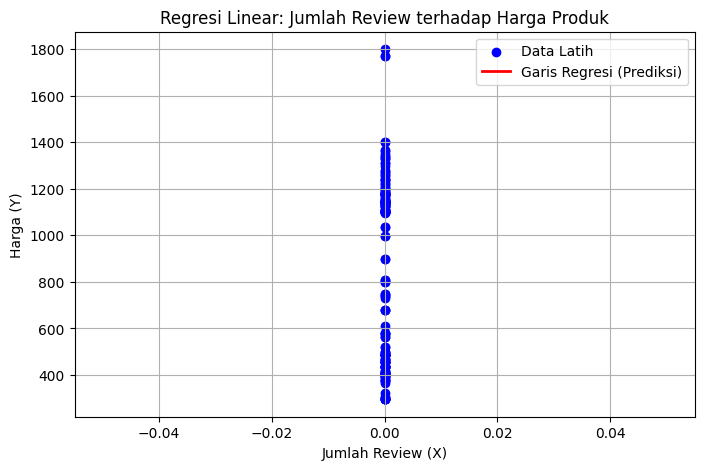

In [10]:
print("\n=== PERSAMAAN REGRESI ===")
print(f"Y = {intercept:.4f} + ({koefisien:.4f}) * X")
print("Keterangan:")
print("Y = Harga Produk")
print("X = Jumlah Review")

# Opsional: Visualisasi garis regresi
plt.figure(figsize=(8, 5))
plt.scatter(x_train, y_train, color='blue', label='Data Latih')
plt.plot(x_test, y_pred, color='red', linewidth=2, label='Garis Regresi (Prediksi)')
plt.xlabel('Jumlah Review (X)')
plt.ylabel('Harga (Y)')
plt.title('Regresi Linear: Jumlah Review terhadap Harga Produk')
plt.legend()
plt.grid(True)
plt.show()